# Module III (completed): CNN digit classification and object detection
A CNN on MNIST digits, then a YOLO-style detector written from scratch on scenes of real digits. Results from `report/syllabus_results/`; analysis in `report/SYLLABUS.md`.

In [1]:
import sys, os, json, inspect
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, matplotlib.image as mpimg
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda n: json.load(open(ROOT / "report" / "syllabus_results" / f"{n}.json"))
def show(name, width=15):
    img = mpimg.imread(ROOT / "report" / "figures" / f"syllabus_{name}.png")
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1])); plt.imshow(img); plt.axis("off"); plt.show()


## CNN on handwritten digits

class DigitCNN(nn.Module):
    """Two conv blocks per resolution (28 -> 14 -> 7), then a small classifier. About 0.4 M parameters."""

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(block(1, 32), block(32, 32), nn.MaxPool2d(2), nn.Dropout(0.15),
                                  block(32, 64), block(64, 64), nn.MaxPool2d(2), nn.Dropout(0.15))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.body(x))

CNN 99.66% (34 errors / 10000)   NumPy MLP 97.85%   parameters 468,010


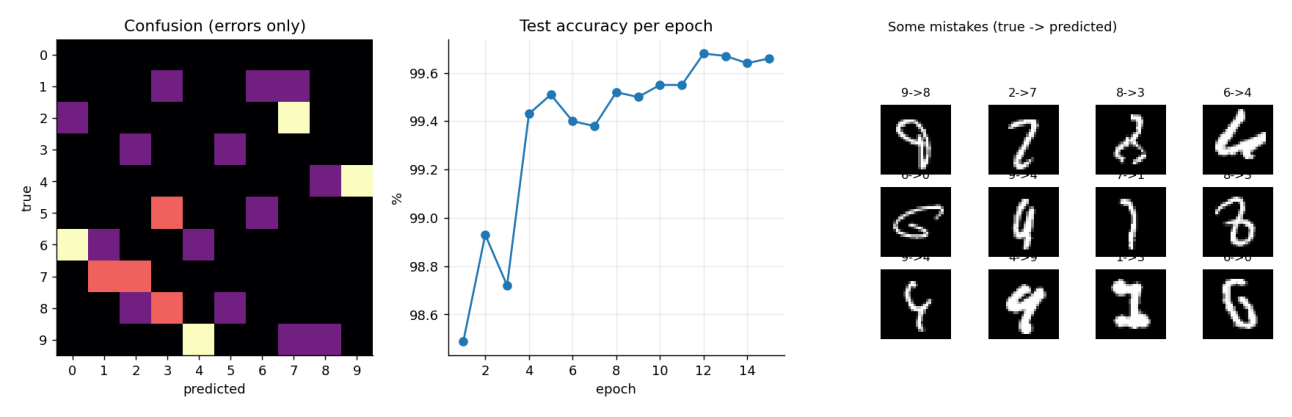

In [2]:
from src.syllabus.digit_cnn import DigitCNN
print(inspect.getsource(DigitCNN))
d = res('digit_cnn')
print(f"CNN {d['test_acc']*100:.2f}% ({d['errors']} errors / {d['test_size']})   NumPy MLP {d['numpy_mlp_acc']*100:.2f}%   parameters {d['params']:,}")
show('digit_cnn')

## Detection scenes: real MNIST digits composed on a canvas
The boxes are measured from the pasted pixels. These four scenes are generated right now from the real MNIST test digits (green = ground truth).

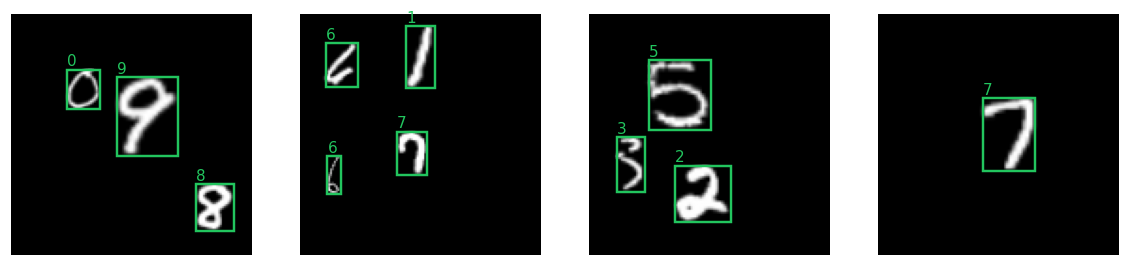

In [3]:
from matplotlib.patches import Rectangle
from src.syllabus.detection.scenes import build_scenes
imgs, boxes = build_scenes(4, 'val')
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, im, bx in zip(axs, imgs, boxes):
    ax.imshow(im, cmap='gray'); ax.axis('off')
    for c, x1, y1, x2, y2 in bx:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec='#22c55e', lw=1.6)); ax.text(x1, y1 - 2, str(int(c)), color='#22c55e')
plt.show()

## The detector, its loss and the metric (written from scratch)

In [4]:
from src.syllabus.detection import yolo_lite, metrics
print(inspect.getsource(yolo_lite.YoloLite)); print(inspect.getsource(yolo_lite.giou)); print(inspect.getsource(yolo_lite.yolo_loss)); print(inspect.getsource(metrics.average_precision))

class YoloLite(nn.Module):
    """About 0.6 M parameters. Output (B, 5 + NC, GRID, GRID)."""

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(cbl(1, 16), cbl(16, 32, 2), cbl(32, 32),            # 64
                                  cbl(32, 64, 2), cbl(64, 64),                        # 32
                                  cbl(64, 128, 2), cbl(128, 128), cbl(128, 128))      # 16 (stride 8)
        self.head = nn.Conv2d(128, 5 + NC, 1)

    def forward(self, x):
        return self.head(self.body(x))

def giou(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Generalised IoU of paired boxes (n,4); in [-1, 1], it still has a gradient when the boxes do not overlap."""
    iw = (torch.min(a[:, 2], b[:, 2]) - torch.max(a[:, 0], b[:, 0])).clamp(min=0)
    ih = (torch.min(a[:, 3], b[:, 3]) - torch.max(a[:, 1], b[:, 1])).clamp(min=0)
    inter = iw * ih
    union = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]) + (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) 

YoloLite  mAP@0.5 99.31%   mAP@[0.5:0.95] 94.10%   441,023 parameters   4989 validation objects


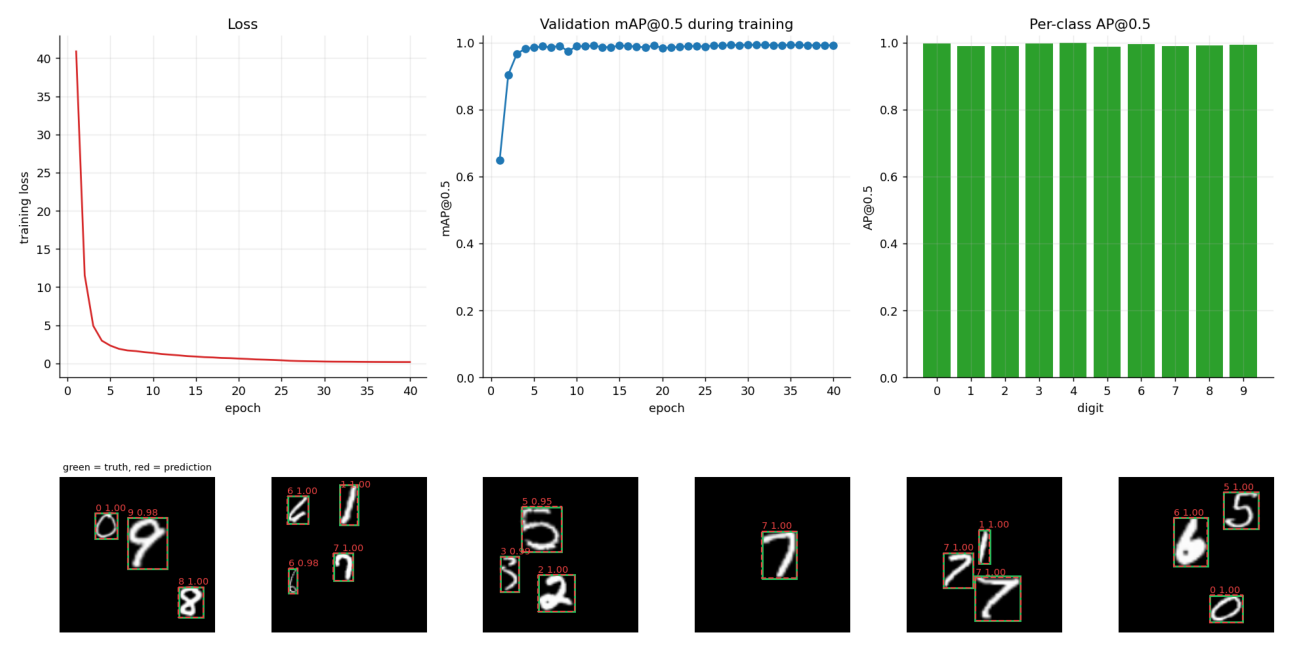

In [5]:
s = res('det_scratch')
print(f"YoloLite  mAP@0.5 {s['map50']*100:.2f}%   mAP@[0.5:0.95] {s['map50_95']*100:.2f}%   {s['params']:,} parameters   {s['val_objects']} validation objects")
show('det_scratch')